   Year  Departure from Average
0  1850                   -0.02
1  1851                    0.18
2  1852                    0.06
3  1853                    0.02
4  1854                   -0.03


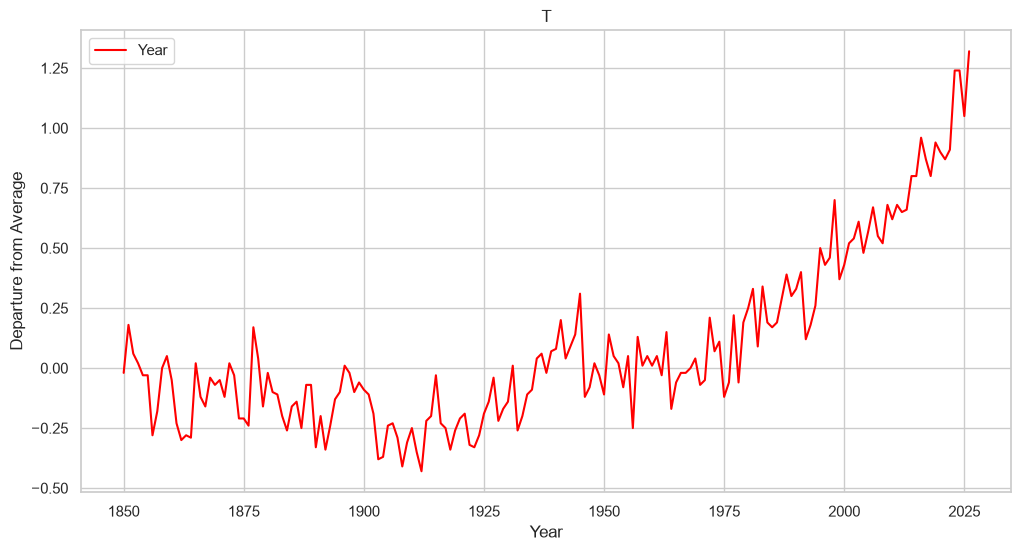

In [1]:
# chickens5 = "Gabe"
# =====================

#Headers: Year,Departure from Average

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


df = pd.read_csv('lsavg.csv')

print(df.head())
## Setup Threshold model row/col

sns.set(style="whitegrid") 

plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x=df['Year'], y=df['Departure from Average'], label='Year', color='red')

plt.xlabel('Year')
plt.ylabel('Departure from Average')
plt.title('T')

plt.show()


# EDA

The NOAA Land/Sea Average Temperature Departures (lsavg.csv) are not absolute because they are global temperature anomalies relative to the 1901-2020 mean.

Climate tipping-point thresholds are relative to pre-industrial levels, which is why the lasavg temps must be converted before any comparison.

--- Analog Windows Used ---
   Window  Path_RMSE_C  Slope_Difference_C_per_year  Annual_Warming_Rate_C  Match_Score
1903-1962     0.342437                     0.011924               0.007315     0.402057
1904-1963     0.348437                     0.011942               0.007296     0.408149
1907-1966     0.406755                     0.012758               0.006480     0.470545
1892-1951     0.402935                     0.014192               0.005047     0.473894
1890-1949     0.427929                     0.014305               0.004933     0.499455
1905-1964     0.442514                     0.012498               0.006740     0.505005
1906-1965     0.450435                     0.012664               0.006574     0.513757
1893-1952     0.476016                     0.014230               0.005009     0.547165

--- Warming Scenario Summary ---
 Horizon_Years  Year  Low_C  Central_C  High_C
            20  2046   2.24       2.30    2.36
            30  2056   2.41       2.50    2.59
     

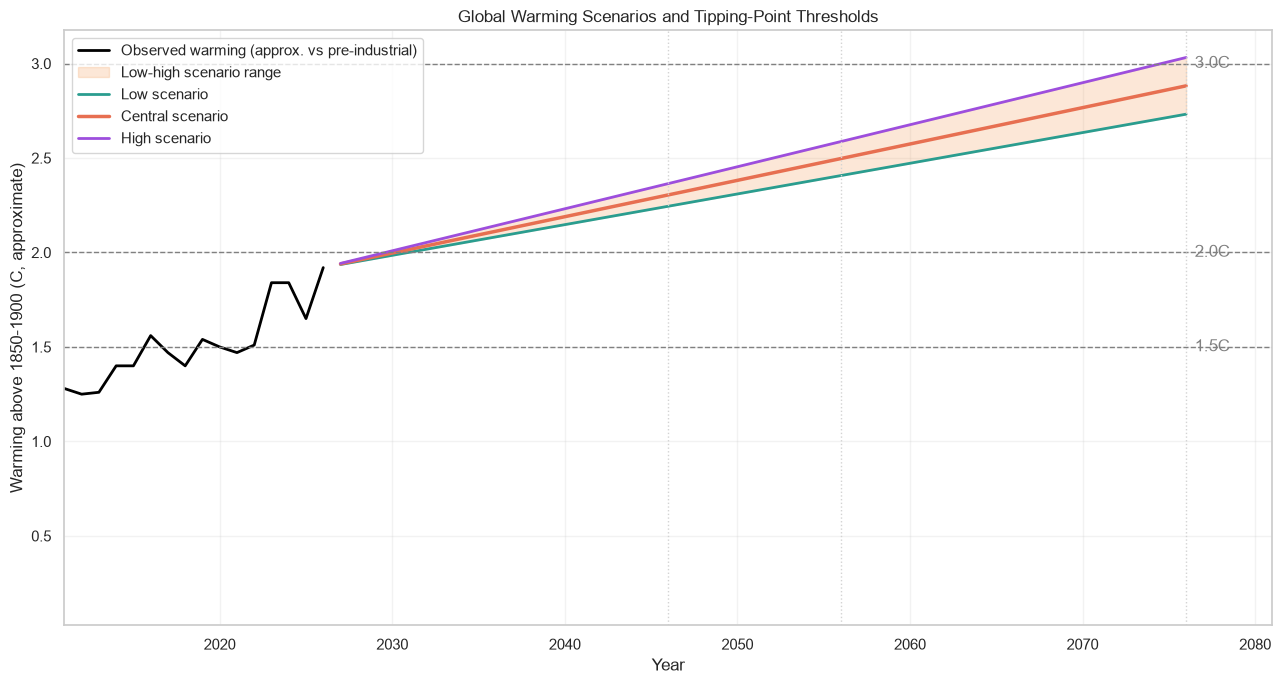

In [ ]:
"""
    Encapsulates annual global warming scenarios relative to an 1850-1900 baseline.
    Projects future trajectories based on historical analogs and compares them 
    against scientifically established Global Mean Surface Temperature (GMST) tipping thresholds.
    """
class ClimateScenarioModel:
   # The source data is an anomaly relative to 1901-2020. 
   # `baseline_offset` converts it to an approximate pre-industrial comparison scale 
   #  so it can be compared with the tipping-point table from above.

    def __init__(self, csv_path='lsavg.csv', baseline_offset=0.6):
        # NOAA NCEI data is typically relative to the 20th century (1901-2020).
        # We add baseline_offset (e.g., +0.6C) to approximate the 1850-1900 pre-industrial 
        # baseline. This aligns the data with IPCC and tipping point literature.
        self.baseline_offset = baseline_offset
        self.df = pd.read_csv(csv_path)
        self.df = self.df[['Year', 'Departure from Average']].dropna()
        self.df = self.df.sort_values('Year').reset_index(drop=True)
        self.df = self.df.rename(columns={'Departure from Average': 'anomaly_vs_1901_2020'})
        self.df['warming_vs_preindustrial'] = (
            self.df['anomaly_vs_1901_2020'] + self.baseline_offset
        )

    #
    @staticmethod
    def _slope(values):
        return np.polyfit(np.arange(len(values)), values, 1)[0]

    @staticmethod
    def _threshold_table():
        return {
            'Low-Latitude Coral Reefs': (1.2, 1.0, 1.5),
            'Greenland Ice Sheet': (1.5, 0.8, 3.0),
            'West Antarctic Ice Sheet': (1.5, 1.0, 3.0),
            'Boreal Permafrost Thaw': (1.5, 1.0, 2.3),
            'Mountain Glaciers': (1.5, 1.1, 2.2),
            'West African Monsoon': (2.0, 1.0, 6.0),
            'EAIS (Wilkes Basin)': (3.0, 2.0, 4.0),
            'Boreal Forest (Southern)': (3.0, 1.5, 5.0),
            'Amazon Rainforest': (3.5, 2.0, 6.0),
            'ENSO Variability': (3.5, 2.5, 6.0),
            'EAIS (Aurora Basin)': (4.0, 3.0, 5.0),
            'AMOC (Partial Collapse)': (4.0, 1.4, 8.0),
            'Boreal Forest (Northern)': (4.0, 1.5, 7.0),
            'Indian Summer Monsoon': (4.5, 3.0, 6.0),
            'AMOC (Total Collapse)': (6.0, 4.0, 8.0),
            'Arctic Winter Sea Ice': (6.3, 4.5, 8.7),
        }

    def find_analogs(self, history_window=15, k=8):
        """Identifies historical rolling windows with warming trajectories most 
        similar to the most recent window.
        
        Matches evaluate both the cumulative path (RMSE) and the linear rate (slope).
        Caveat: Past atmospheric forcing (GHG concentrations) differs from the present, 
        so historical analogs may produce conservative forward-looking rates.
        """
        values = self.df['warming_vs_preindustrial'].to_numpy()
        current = values[-history_window:]
        current_path = current - current[0]
        current_slope = self._slope(current)
        current_start = len(values) - history_window
        candidates = []

        for start in range(0, current_start - history_window + 1):
            candidate = values[start:start + history_window]
            candidate_path = candidate - candidate[0]
            path_rmse = np.sqrt(np.mean((candidate_path - current_path) ** 2))
            slope_difference = abs(self._slope(candidate) - current_slope)
            score = path_rmse + 5 * slope_difference
            candidates.append({
                'Window': f"{int(self.df['Year'].iloc[start])}-{int(self.df['Year'].iloc[start + history_window - 1])}",
                'Path_RMSE_C': path_rmse,
                'Slope_Difference_C_per_year': slope_difference,
                'Annual_Warming_Rate_C': self._slope(candidate),
                'Match_Score': score,
            })

        if not candidates:
            raise ValueError('Not enough history to construct analog windows.')

        analogs = pd.DataFrame(candidates).sort_values('Match_Score').head(k).reset_index(drop=True)
        return analogs

    def build_scenarios(self, horizons=(20, 30, 50), history_window=15, k=8):
        """Create low, central, and high trajectories for 20-, 30-, and 50-year horizons."""
        horizons = tuple(sorted(set(horizons)))
        if any(horizon <= 0 for horizon in horizons):
            raise ValueError('All forecast horizons must be positive integers.')

        self.analogs = self.find_analogs(history_window=history_window, k=k)
        recent_values = self.df['warming_vs_preindustrial'].tail(history_window).to_numpy()
        central_rate = self._slope(recent_values)
        analog_rates = self.analogs['Annual_Warming_Rate_C'].to_numpy()
        rate_spread = max(np.std(analog_rates), 0.003)
        scenario_rates = {
            'Low': max(0.0, central_rate - rate_spread),
            'Central': central_rate,
            'High': central_rate + rate_spread,
        }

        last_year = int(self.df['Year'].iloc[-1])
        current_warming = float(self.df['warming_vs_preindustrial'].iloc[-1])
        forecast_years = np.arange(last_year + 1, last_year + max(horizons) + 1)
        forecast = pd.DataFrame({'Year': forecast_years})

        for scenario, annual_rate in scenario_rates.items():
            forecast[scenario] = current_warming + annual_rate * np.arange(1, len(forecast_years) + 1)

        self.scenario_rates = pd.DataFrame(
            [{'Scenario': scenario, 'Annual_Warming_Rate_C': rate} for scenario, rate in scenario_rates.items()]
        )
        self.forecast = forecast
        self.horizons = horizons
        self.threshold_summary = self._threshold_summary()
        return forecast

    def _threshold_summary(self):
        """
        Calculates the estimated year each scenario crosses key tipping point thresholds.
        
        Note: The 'Crossing_Year' indicates the point of first intersection. 
        Physical tipping elements generally require sustained temperature overshoots 
        rather than instantaneous spikes to trigger irreversible collapse.
        """
        rows = []
        for element, (central_threshold, low_threshold, high_threshold) in self._threshold_table().items():
            row = {
                'Tipping_Element': element,
                'Central_Estimate_C': central_threshold,
                'Range_Low_C': low_threshold,
                'Range_High_C': high_threshold,
            }
            for scenario in ['Low', 'Central', 'High']:
                crossed = self.forecast.loc[self.forecast[scenario] >= central_threshold, 'Year']
                row[f'{scenario}_Crossing_Year'] = int(crossed.iloc[0]) if not crossed.empty else pd.NA
            rows.append(row)
        return pd.DataFrame(rows).sort_values('Central_Estimate_C').reset_index(drop=True)

    def horizon_summary(self):
        rows = []
        for horizon in self.horizons:
            values = self.forecast.iloc[horizon - 1]
            rows.append({
                'Horizon_Years': horizon,
                'Year': int(values['Year']),
                'Low_C': round(values['Low'], 2),
                'Central_C': round(values['Central'], 2),
                'High_C': round(values['High'], 2),
            })
        return pd.DataFrame(rows)

    def plot_forecast(self):
        plt.figure(figsize=(13, 7))
        plt.plot(
            self.df['Year'],
            self.df['warming_vs_preindustrial'],
            color='black',
            linewidth=2,
            label='Observed warming (approx. vs pre-industrial)',
        )
        plt.fill_between(self.forecast['Year'], self.forecast['Low'], self.forecast['High'], color='#f4a261', alpha=0.25, label='Low-high scenario range')
        plt.plot(self.forecast['Year'], self.forecast['Low'], color='#2a9d8f', linewidth=2, label='Low scenario')
        plt.plot(self.forecast['Year'], self.forecast['Central'], color='#e76f51', linewidth=2.5, label='Central scenario')
        plt.plot(self.forecast['Year'], self.forecast['High'], color='#9d4edd', linewidth=2, label='High scenario')

        for threshold, label in [(1.5, '1.5C'), (2.0, '2.0C'), (3.0, '3.0C')]:
            plt.axhline(threshold, color='gray', linestyle='--', linewidth=1)
            plt.text(self.forecast['Year'].iloc[-1] + 0.5, threshold, label, va='center', color='gray')

        for horizon in self.horizons:
            year = int(self.forecast['Year'].iloc[horizon - 1])
            plt.axvline(year, color='lightgray', linestyle=':', linewidth=1)

        plt.title('Global Warming Scenarios and Tipping-Point Thresholds')
        plt.xlabel('Year')
        plt.ylabel('Warming above 1850-1900 (C, approximate)')
        plt.xlim(self.df['Year'].iloc[-1] - 15, self.forecast['Year'].iloc[-1] + 5)
        plt.legend(loc='upper left')
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()


model = ClimateScenarioModel()
forecast = model.build_scenarios(horizons=(20, 30, 50), history_window=60, k=8)

print('--- Analog Windows Used ---')
print(model.analogs.to_string(index=False))

print('\n--- Warming Scenario Summary ---')
print(model.horizon_summary().to_string(index=False))

print('\n--- Earliest Central-Scenario Threshold Crossings ---')
print(model.threshold_summary[['Tipping_Element', 'Central_Estimate_C', 'Central_Crossing_Year']].head(10).to_string(index=False))

model.plot_forecast()

A good working assumption is that the 1901-2020 mean sits roughly 0.6°C above the 1850-1900 pre-industrial baseline. For example:

- observed anomaly (1901-2020 baseline) = x
- approximate warming vs pre-industrial = x + 0.6

This is why evaluating a 2025 value near 1.32°C against a 1.5°C threshold without adjustment is misleading. It should be interpreted as roughly 1.9°C above pre-industrial, not 1.32°C.

The model below therefore uses a converted temperature series for forecasting and thresholds, while still using the original anomaly series for historical trend matching.

$$d(x, X_i) = \sqrt{\sum_{j=1}^{n} (x_j - X_{ij})^2}$$

where d(x, X_i) is the Euclidean distance between a data point x and a reference point X_i; it is the square root of the sum of squared differences across all n dimensions.